In [89]:
import torchvision.datasets as dsets
import torchvision.transforms as transforms

In [90]:
train_dataset = dsets.MNIST(
    root="./data", train=True, transform=transforms.ToTensor(), download=True
)
test_dataset = dsets.MNIST(
    root="./data", train=False, transform=transforms.ToTensor(), download=True
)

In [91]:
train_dataset.data.shape

torch.Size([60000, 28, 28])

In [92]:
import matplotlib.pyplot as plt

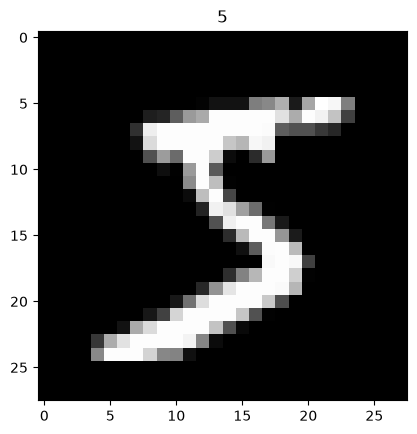

In [93]:
plt.imshow(train_dataset.data[0].numpy(), cmap="gray")
plt.title("%d" % train_dataset.targets[0])
plt.show()

In [94]:
input_size = 28 * 28
hidden_size = 500
num_classes = 10
num_epochs = 5
batch_size = 100
learning_rate = 0.001

In [95]:
import torch.utils.data as Data

In [96]:
train_loader = Data.DataLoader(
    dataset=train_dataset, batch_size=batch_size, shuffle=True
)

test_loader = Data.DataLoader(
    dataset=test_dataset, batch_size=batch_size, shuffle=False
)

In [97]:
import torch.nn as nn

In [98]:
class Model(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(Model, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

In [99]:
model = Model(input_size, hidden_size, num_classes)

In [100]:
import torch.optim as optim

In [101]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [102]:
from torch.autograd import Variable

In [103]:
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = Variable(images.view(-1, 28 * 28))
        labels = Variable(labels)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i + 1) % 100 == 0:
            print("Epoch: %d, Batch: %d, Loss: %.4f" % (epoch + 1, i + 1, loss.item()))

Epoch: 1, Batch: 100, Loss: 0.3713
Epoch: 1, Batch: 200, Loss: 0.2585
Epoch: 1, Batch: 300, Loss: 0.2238
Epoch: 1, Batch: 400, Loss: 0.0901
Epoch: 1, Batch: 500, Loss: 0.1215
Epoch: 1, Batch: 600, Loss: 0.1393
Epoch: 2, Batch: 100, Loss: 0.0803
Epoch: 2, Batch: 200, Loss: 0.0336
Epoch: 2, Batch: 300, Loss: 0.2221
Epoch: 2, Batch: 400, Loss: 0.0762
Epoch: 2, Batch: 500, Loss: 0.0880
Epoch: 2, Batch: 600, Loss: 0.1722
Epoch: 3, Batch: 100, Loss: 0.0371
Epoch: 3, Batch: 200, Loss: 0.0760
Epoch: 3, Batch: 300, Loss: 0.0609
Epoch: 3, Batch: 400, Loss: 0.1122
Epoch: 3, Batch: 500, Loss: 0.0569
Epoch: 3, Batch: 600, Loss: 0.1065
Epoch: 4, Batch: 100, Loss: 0.0187
Epoch: 4, Batch: 200, Loss: 0.0763
Epoch: 4, Batch: 300, Loss: 0.0307
Epoch: 4, Batch: 400, Loss: 0.0502
Epoch: 4, Batch: 500, Loss: 0.0382
Epoch: 4, Batch: 600, Loss: 0.0691
Epoch: 5, Batch: 100, Loss: 0.1342
Epoch: 5, Batch: 200, Loss: 0.0252
Epoch: 5, Batch: 300, Loss: 0.0455
Epoch: 5, Batch: 400, Loss: 0.0473
Epoch: 5, Batch: 500

In [104]:
import torch

In [ ]:
correct = 0
total = 0
for images, labels in test_loader:
    images = Variable(images.view(-1, 28 * 28))
    outputs = model(images)
    _, pred = torch.max(outputs.data, 1)
    correct += (pred == labels).sum()
    total += labels.size(0)
print("Accuracy: %.3f %%" % (100.0 * float(correct) / float(total)))

Accuracy: 98.010
